# 1 · Worlds, potentials, inference and learning

We build the simplest neural Markov logic network there is, and use it to meet every piece of the theory:

1. **the relational language**: constants, predicates, ground atoms;
2. **possible worlds**: a world is a truth assignment to the ground atoms, a binary vector $y$;
3. **potentials**: features of worlds, here first a symbolic one;
4. **the model**: the maximum-entropy distribution $p(y) \propto \exp\big(\sum_k \beta_k\,\phi_k(y)\big)$;
5. **inference**: marginals, MAP, samples, expectations;
6. **learning**: data statistics minus model expectations, computed exactly or estimated with Gibbs sampling;
7. **why neural potentials**: data that no fixed statistic can describe.

The data are worlds over $n$ individuals in which each individual has a property independently with probability $p$, so the number of individuals with the property follows a binomial distribution.

In [1]:
import math

import matplotlib.pyplot as plt
import torch

import nmln

torch.manual_seed(0)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
DATA, MODEL, EXACT, NEURAL = "#9aa5b1", "#2563eb", "#dc2626", "#16a34a"

## 1. The relational language

A function-free first-order language has **constants**, which name individuals and live in **domains**, and **predicates**, which describe properties of and relations between individuals.

Here there is one domain `v` with $n = 10$ constants, and one unary predicate `s(X)`: "individual $X$ is a success". The `Ontology` puts the language together.

In [2]:
n = 10
v = nmln.Domain("v", list(range(n)))
s = nmln.Predicate("s", [v])
ontology = nmln.Ontology([v], [s])
ontology

Ontology: 10 ground atoms, 10 variables
  domains:    v (10)
  predicates: s(v)

## 2. Ground atoms and possible worlds

A **ground atom** applies a predicate to constants: `s(0)`, `s(1)`, …. All of them together form the **Herbrand base**. A **possible world** assigns a truth value to every ground atom, so once the atoms are put in a fixed order (the ontology fixes it), a world is a binary vector $y \in \{0, 1\}^D$ with $D$ ground atoms.

In [3]:
print("ground atoms:   ", [ontology.atom(i) for i in range(ontology.num_atoms)])
print("position of s(3):", ontology.atom_index("s(3)"))

y = ontology.world(["s(0)", "s(3)", "s(7)"])
print("the world y:    ", y.int().tolist())
print("its true atoms: ", ontology.true_atoms(y))
print("number of possible worlds: 2 **", ontology.num_atoms, "=", 2 ** ontology.num_atoms)

ground atoms:    ['s(0)', 's(1)', 's(2)', 's(3)', 's(4)', 's(5)', 's(6)', 's(7)', 's(8)', 's(9)']
position of s(3): 3
the world y:     [1, 0, 0, 1, 0, 0, 0, 1, 0, 0]
its true atoms:  ['s(0)', 's(3)', 's(7)']
number of possible worlds: 2 ** 10 = 1024


The **random variables** of a world are groups of atoms. Atoms of a predicate that we do not declare otherwise are independent Boolean variables (later notebooks declare categorical variables, e.g. which digit an image shows).

In [4]:
variables = ontology.variables
print(len(variables), "variables, e.g.", variables.name(0), "with values", variables.groups[0].values)

10 variables, e.g. s(0) with values [True, False]


## 3. The data: observed worlds

A dataset is a collection of worlds $\{y^{(1)}, \dots, y^{(N)}\}$. We sample $N = 2000$ worlds in which each atom is true with probability $p = 0.3$, independently; the number of true atoms in a world is then $\mathrm{Binomial}(n, p)$.

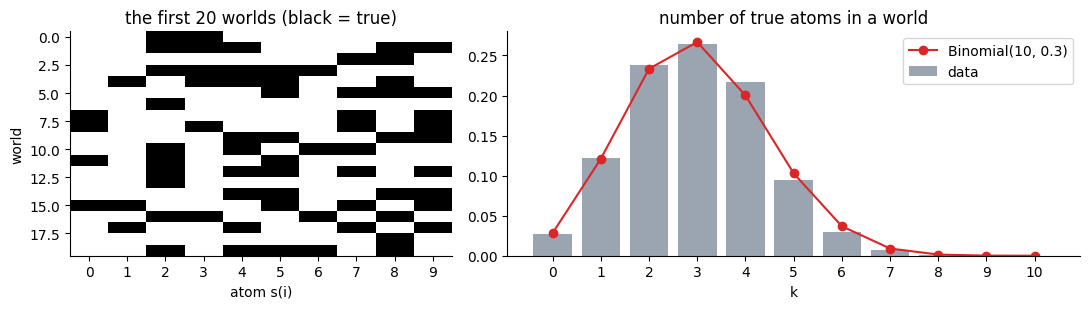

In [5]:
p = 0.3
data = (torch.rand(2000, n) < p).float()

k = torch.arange(n + 1)
binomial = torch.tensor([math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(n + 1)])

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.5]})
left.imshow(data[:20], cmap="Greys", aspect="auto", vmin=0, vmax=1)
left.set(title="the first 20 worlds (black = true)", xlabel="atom s(i)", ylabel="world", xticks=range(n))
right.bar(k, torch.bincount(data.sum(1).long(), minlength=n + 1) / len(data), color=DATA, label="data")
right.plot(k, binomial, "o-", color=EXACT, label=f"Binomial({n}, {p})")
right.set(title="number of true atoms in a world", xlabel="k", xticks=k)
right.legend()
plt.tight_layout()
plt.show()

## 4. A symbolic potential

A **potential** is a feature of a world. A symbolic potential states a property with a formula and measures how often it holds: its **statistic** is the fraction of the formula's groundings that are true in the world.

The formula `s(X)` has one grounding per constant, so its statistic is the fraction of true atoms,

$$\phi(y) = \frac{1}{n} \sum_{X} s(X).$$

In [6]:
fraction = nmln.SymbolicPotential(ontology, "s(X)", beta=0.0)
print(fraction)
print("groundings:  ", fraction.groundings(limit=4), "...")
print("φ(y) for the world above:", round(fraction.statistic(y).item(), 3))
print("average of φ over the data:", round(fraction.statistic(data).mean().item(), 4))

SymbolicPotential(
  's(X)', groundings=10, normalize='mean'
  (module): _Formula()
)
groundings:   ['s(0)', 's(1)', 's(2)', 's(3)'] ...
φ(y) for the world above: 0.3
average of φ over the data: 0.2966


## 5. The model: maximum entropy gives an exponential family

Among all distributions whose expected statistic matches the data, **maximum entropy** picks the least committed one. Its solution is an exponential family, one weight $\beta$ per statistic:

$$p_\beta(y) = \frac{\exp\big(\beta\,\phi(y)\big)}{Z(\beta)}, \qquad Z(\beta) = \sum_{y} \exp\big(\beta\,\phi(y)\big).$$

With a symbolic statistic this is a Markov logic network. Here $\exp(\beta\,\phi(y)) = \prod_i \exp(\tfrac{\beta}{n} y_i)$, so the atoms are independent with $P(y_i = 1) = \sigma(\beta / n)$, and the number of true atoms is binomial again. Matching the data's average statistic $\hat p$ gives the weight in closed form: $\beta^* = n \cdot \mathrm{logit}(\hat p)$.

An `NMLN` is just the ontology plus its potentials. To ask it questions we need an **inference engine**; with $2^{10}$ worlds we can enumerate all of them with `Exact`.

1024 possible worlds enumerated


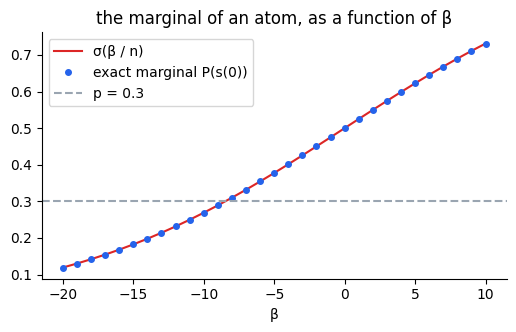

moment matching: β* = n · logit(0.297) = -8.635


In [7]:
model = nmln.NMLN(ontology, [fraction])
exact = nmln.Exact(model)
print(len(exact.worlds), "possible worlds enumerated")

betas = torch.linspace(-20, 10, 31)
marginal = []
for beta in betas:
    fraction.beta.data.fill_(float(beta))
    marginal.append(exact.marginals()[0].item())

plt.plot(betas, torch.sigmoid(betas / n), color=EXACT, label="σ(β / n)")
plt.plot(betas, marginal, "o", color=MODEL, ms=4, label="exact marginal P(s(0))")
plt.axhline(p, color=DATA, ls="--", label=f"p = {p}")
plt.xlabel("β")
plt.title("the marginal of an atom, as a function of β")
plt.legend()
plt.show()

p_hat = data.mean()
beta_star = n * torch.logit(p_hat)
print(f"moment matching: β* = n · logit({p_hat:.3f}) = {beta_star:.3f}")

## 6. Inference: four uses of the same distribution

Every engine answers the same questions with the same calls: **marginals** (the probability of each atom), **MAP** (the most probable world), **samples** (generation), and, from these, **expectations** of statistics. Observed atoms are passed as `evidence`.

In [8]:
fraction.beta.data.fill_(float(beta_star))

print("marginals:    ", exact.marginals().numpy().round(3))
print("MAP world:    ", ontology.true_atoms(exact.map()), "(every atom is more likely false than true)")
print("three samples:", [ontology.true_atoms(world) for world in exact.sample(3)])
print("E_p[φ]:       ", round(exact.marginals().mean().item(), 4), " vs the data's", round(p_hat.item(), 4))

evidence = ontology.evidence({"s(0)": 1, "s(1)": 0})
print("marginals given s(0) = 1 and s(1) = 0:", exact.marginals(evidence=evidence).numpy().round(3))

marginals:     [0.297 0.297 0.297 0.297 0.297 0.297 0.297 0.297 0.297 0.297]
MAP world:     [] (every atom is more likely false than true)
three samples: [['s(1)', 's(5)'], ['s(0)', 's(1)', 's(4)'], ['s(3)', 's(7)', 's(8)', 's(9)']]
E_p[φ]:        0.2966  vs the data's 0.2966
marginals given s(0) = 1 and s(1) = 0: [1.    0.    0.297 0.297 0.297 0.297 0.297 0.297 0.297 0.297]


Enumerating worlds does not scale: $2^{D}$ worlds. **Gibbs sampling** is the general alternative: a Markov chain that resamples one variable at a time from its distribution given all the others. Started from the all-false world, the chains move towards typical worlds; averaging over the visited worlds estimates the marginals.

Here the atoms are independent, so a single sweep already draws every atom from its exact marginal: the chains reach equilibrium after one sweep and then fluctuate around the expected score. With interacting atoms (notebooks 3 and 4) this takes much longer.

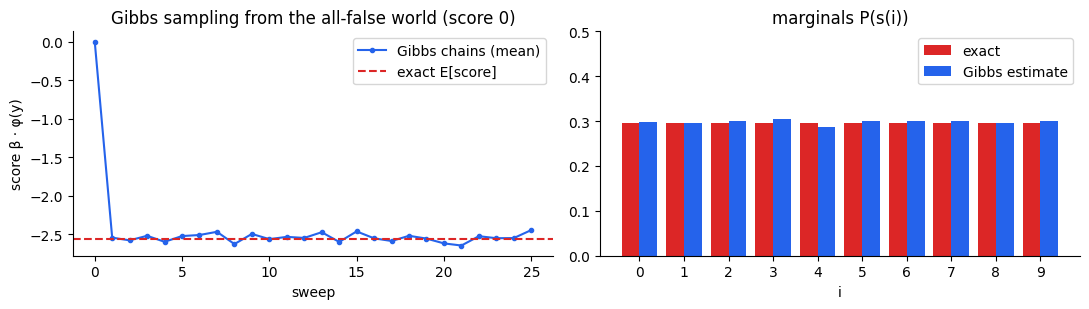

In [9]:
gibbs = nmln.Gibbs(model, num_chains=200, burn_in=10, num_sweeps=50)
worlds, trace = gibbs.trace(500, num_sweeps=25)  # 500 chains, 25 sweeps: the score after every sweep

with torch.no_grad():
    expected_score = (exact.probabilities() * model.score(exact.worlds)).sum()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
left.plot(range(0, 26), [0.0] + trace.mean(-1).tolist(), "o-", color=MODEL, ms=3, label="Gibbs chains (mean)")
left.axhline(expected_score, color=EXACT, ls="--", label="exact E[score]")
left.set(title="Gibbs sampling from the all-false world (score 0)", xlabel="sweep", ylabel="score β · φ(y)")
left.legend(loc="upper right")
width = 0.4
right.bar(torch.arange(n) - width / 2, exact.marginals(), width, color=EXACT, label="exact")
right.bar(torch.arange(n) + width / 2, gibbs.marginals(), width, color=MODEL, label="Gibbs estimate")
right.set(title="marginals P(s(i))", xlabel="i", xticks=range(n), ylim=(0, 0.5))
right.legend()
plt.tight_layout()
plt.show()

## 7. Learning: data statistics minus model expectations

The log-likelihood of a world has gradient

$$\frac{\partial}{\partial \beta} \log p_\beta(y) = \phi(y) - \mathbb{E}_{p_\beta}[\phi],$$

the statistic of the data minus its expectation under the model. Averaged over the data, it vanishes exactly when the model's expected statistic matches the data's: maximum likelihood is moment matching, and lands on the maximum-entropy weight $\beta^*$.

`MaximumLikelihood(engine).loss(batch)` is $-\log p_\beta$ of a batch, computed exactly by the engine. Here is the training loop, written out, starting from $\beta = 0$:

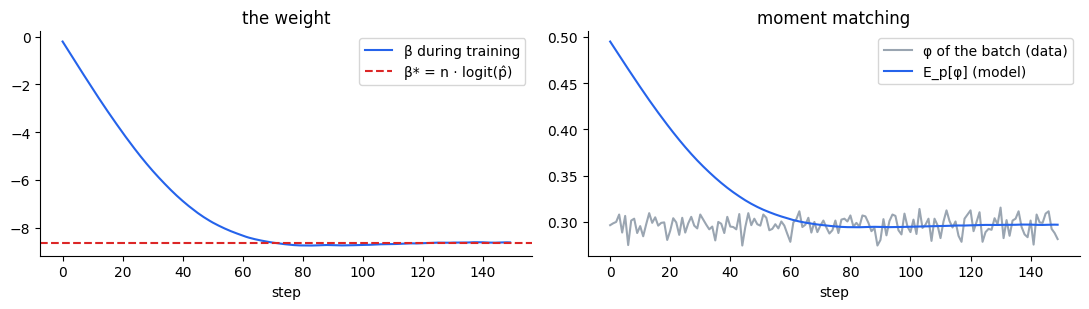

learned β = -8.617, β* = -8.635


In [10]:
fraction.beta.data.fill_(0.0)
learner = nmln.MaximumLikelihood(exact)
optimizer = torch.optim.Adam(model.parameters(), lr=0.2)
loader = torch.utils.data.DataLoader(data, batch_size=200, shuffle=True)

history = {"beta": [], "data": [], "model": []}
for epoch in range(15):
    for batch in loader:
        loss = learner.loss(batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history["beta"].append(fraction.beta.item())
        history["data"].append(fraction.statistic(batch).mean().item())
        history["model"].append(exact.marginals().mean().item())  # E_p[φ] for this statistic

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
left.plot(history["beta"], color=MODEL, label="β during training")
left.axhline(beta_star, color=EXACT, ls="--", label="β* = n · logit(p̂)")
left.set(title="the weight", xlabel="step")
left.legend()
right.plot(history["data"], color=DATA, label="φ of the batch (data)")
right.plot(history["model"], color=MODEL, label="E_p[φ] (model)")
right.set(title="moment matching", xlabel="step")
right.legend()
plt.tight_layout()
plt.show()
print(f"learned β = {fraction.beta.item():.3f}, β* = {beta_star:.3f}")

## 8. Learning from samples: persistent contrastive divergence

Computing $\mathbb{E}_{p_\beta}[\phi]$ exactly needs $Z$, which is out of reach for most languages. **Contrastive learning** estimates it from samples instead. `Contrastive(Gibbs(model))` keeps persistent Gibbs chains: after each parameter update they continue for a sweep from where they were, so they follow the model as it changes. Its loss,

$$\text{mean}_{y \sim \text{chains}}\, \beta\phi(y) \;-\; \text{mean}_{y \sim \text{data}}\, \beta\phi(y),$$

has gradient "model expectation minus data statistic", estimated. It can also corrupt the data with training noise (`noise_scale`), which keeps learned distributions from becoming too deterministic; we switch it off here to compare with exact learning.

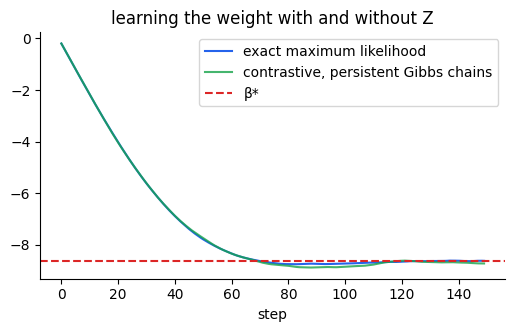

In [11]:
fraction_cd = nmln.SymbolicPotential(ontology, "s(X)", beta=0.0)
model_cd = nmln.NMLN(ontology, [fraction_cd])
contrastive = nmln.Contrastive(nmln.Gibbs(model_cd), noise_scale=0.0)
optimizer = torch.optim.Adam(model_cd.parameters(), lr=0.2)

betas_cd = []
for epoch in range(15):
    for batch in loader:
        loss = contrastive.loss(batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        betas_cd.append(fraction_cd.beta.item())

plt.plot(history["beta"], color=MODEL, label="exact maximum likelihood")
plt.plot(betas_cd, color=NEURAL, alpha=0.8, label="contrastive, persistent Gibbs chains")
plt.axhline(beta_star, color=EXACT, ls="--", label="β*")
plt.xlabel("step")
plt.title("learning the weight with and without Z")
plt.legend()
plt.show()

## 9. Why neural potentials?

Maximum entropy **binds** given features to the data, but someone has to choose the features. Suppose half of the worlds come from $p = 0.1$ and half from $p = 0.9$: the number of true atoms is bimodal. With the fraction of true atoms as its only statistic, the model can only be a binomial, which has one mode, so no weight fits these data.

A **neural potential** learns the feature itself. `WorldMLPPotential` is an MLP that reads the whole world; training it by maximum likelihood also selects which statistic to bind (the thesis calls this minimum entropy over features). Here we train both models with `fit`, which runs a PyTorch Lightning trainer.

In [12]:
bimodal = torch.cat([torch.rand(1000, n) < 0.1, torch.rand(1000, n) < 0.9]).float()
bimodal_loader = torch.utils.data.DataLoader(bimodal, batch_size=200, shuffle=True)

symbolic = nmln.NMLN(ontology, [nmln.SymbolicPotential(ontology, "s(X)", beta=0.0)])
neural = nmln.NMLN(ontology, [nmln.WorldMLPPotential(ontology, hidden_size=32)])
for m in (symbolic, neural):
    losses = nmln.MaximumLikelihood(nmln.Exact(m), lr=0.02).fit(bimodal_loader, epochs=60, accelerator="cpu")
    print(f"{type(m.potentials[0]).__name__:22s} negative log-likelihood per world: {losses[-1]:.3f}")

SymbolicPotential      negative log-likelihood per world: 6.932


WorldMLPPotential      negative log-likelihood per world: 3.975


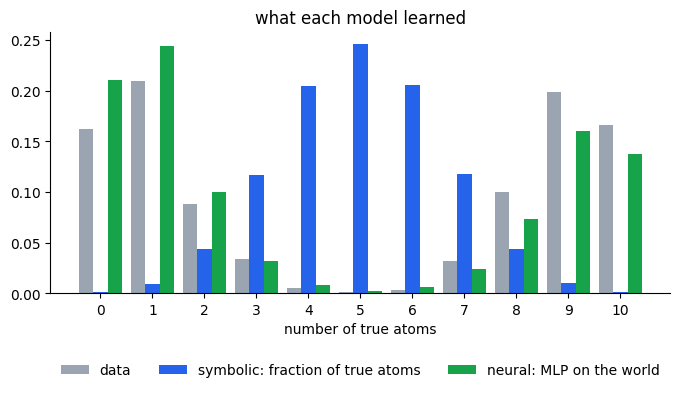

In [13]:
def count_distribution(model):
    engine = nmln.Exact(model)
    return torch.bincount(engine.worlds.sum(1).long(), weights=engine.probabilities(), minlength=n + 1)

width = 0.28
plt.figure(figsize=(8, 3.4))
plt.bar(k - width, torch.bincount(bimodal.sum(1).long(), minlength=n + 1) / len(bimodal), width, color=DATA, label="data")
plt.bar(k, count_distribution(symbolic), width, color=MODEL, label="symbolic: fraction of true atoms")
plt.bar(k + width, count_distribution(neural), width, color=NEURAL, label="neural: MLP on the world")
plt.xticks(k)
plt.xlabel("number of true atoms")
plt.title("what each model learned")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
plt.show()

What did the neural potential learn? Plotting its score $\phi(y)$ for every possible world against the number of true atoms shows the feature it found: high scores at both ends, low in the middle, which no linear function of the count can do.

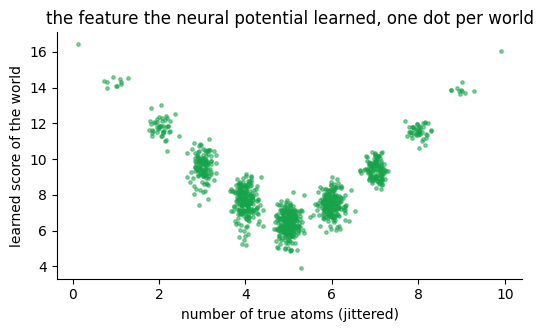

In [14]:
worlds = nmln.Exact(neural).worlds
with torch.no_grad():
    scores = neural.score(worlds)
plt.scatter(worlds.sum(1) + 0.15 * torch.randn(len(worlds)), scores, s=6, color=NEURAL, alpha=0.5)
plt.xlabel("number of true atoms (jittered)")
plt.ylabel("learned score of the world")
plt.title("the feature the neural potential learned, one dot per world")
plt.show()

## Summary

- An **ontology** defines the language and the possible worlds; a world is a binary vector over ground atoms.
- A **potential** is a feature of worlds; a symbolic one measures how often a formula holds.
- **Maximum entropy** turns features into the exponential family $p(y) \propto \exp(\sum_k \beta_k \phi_k(y))$; with symbolic features it is a Markov logic network.
- **Inference** engines answer marginals, MAP and samples with the same calls; `Exact` enumerates, `Gibbs` samples.
- **Learning** follows data statistics minus model expectations, computed exactly (`MaximumLikelihood`) or from persistent chains (`Contrastive`).
- **Neural potentials** learn the features themselves, when no fixed statistic describes the data.

Next: notebook 2 attaches images to constants and combines a neural predicate with a symbolic program.

## Exercises

1. Change $p$ and $n$, retrain the model of section 7, and check that the learned $\beta$ is $n \cdot \mathrm{logit}(\hat p)$.
2. Add a second symbolic potential, `s(X) and s(Y)`, to the symbolic model of section 9. Can a Markov logic network with these two rules fit the bimodal data? Why?
3. With $n = 30$ there are $2^{30}$ worlds and `Exact` refuses. Learn the weight of `s(X)` with `Contrastive(Gibbs(model))` and `fit` instead.

<details>
<summary>Solution 2</summary>

The statistic of `s(X) and s(Y)` is the fraction of true pairs, $(c / n)^2$ for $c$ true atoms (pairs with $X = Y$ included). The model becomes $p(y) \propto \exp(\beta_1 c / n + \beta_2 (c / n)^2)$, and with $\beta_2 > 0$ it is bimodal. The weights come out near $(-31, +31)$, and the fit (negative log-likelihood about 4.1 per world) is almost as good as the MLP's: the right symbolic feature does the job, but someone had to know it.

```python
pairs = nmln.NMLN(ontology, [nmln.SymbolicPotential(ontology, "s(X)", beta=0.0),
                             nmln.SymbolicPotential(ontology, "s(X) and s(Y)", beta=0.0)])
nmln.MaximumLikelihood(nmln.Exact(pairs), lr=0.5).fit(bimodal_loader, epochs=60, accelerator="cpu")
print([p.beta.item() for p in pairs.potentials])
plt.bar(k, count_distribution(pairs)); plt.show()
```
</details>

<details>
<summary>Solution 3</summary>

```python
big = nmln.Domain("v", list(range(30)))
big_ontology = nmln.Ontology([big], [nmln.Predicate("s", [big])])
big_fraction = nmln.SymbolicPotential(big_ontology, "s(X)", beta=0.0)
big_data = (torch.rand(2000, 30) < 0.3).float()
nmln.Contrastive(nmln.Gibbs(nmln.NMLN(big_ontology, [big_fraction])), lr=0.5, noise_scale=0.0).fit(
    torch.utils.data.DataLoader(big_data, batch_size=200, shuffle=True), epochs=30, accelerator="cpu")
print(big_fraction.beta.item(), 30 * torch.logit(big_data.mean()).item())  # both close to -25.6
```
</details>